In [27]:
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)

# **Laplacian Filter**

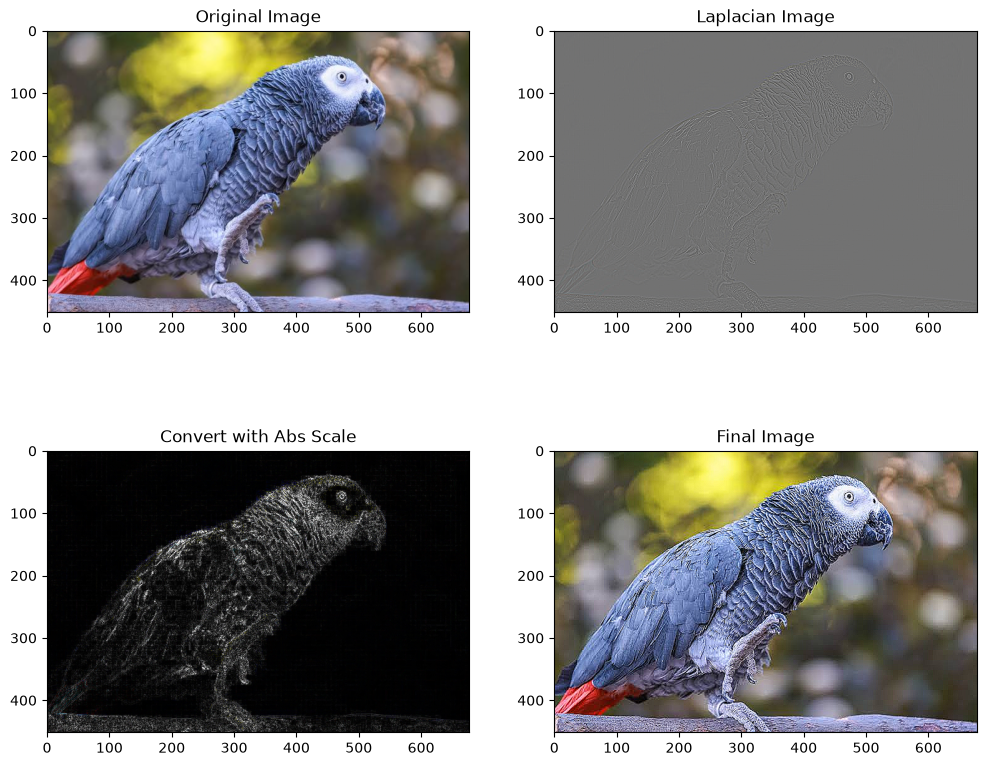

In [28]:
imgFile = '../images/parrot.jpg'

img = cv2.cvtColor(cv2.imread(imgFile), cv2.COLOR_BGR2RGB)

manual_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

laplacian_manual = cv2.filter2D(img, cv2.CV_64F, manual_kernel)
laplacian_view = cv2.normalize(laplacian_manual, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
laplacian_abs = cv2.convertScaleAbs(laplacian_manual)

finalImage = np.clip(img.astype(np.float64) - laplacian_manual, 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian_view), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_abs), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage), plt.title('Final Image')
plt.show()

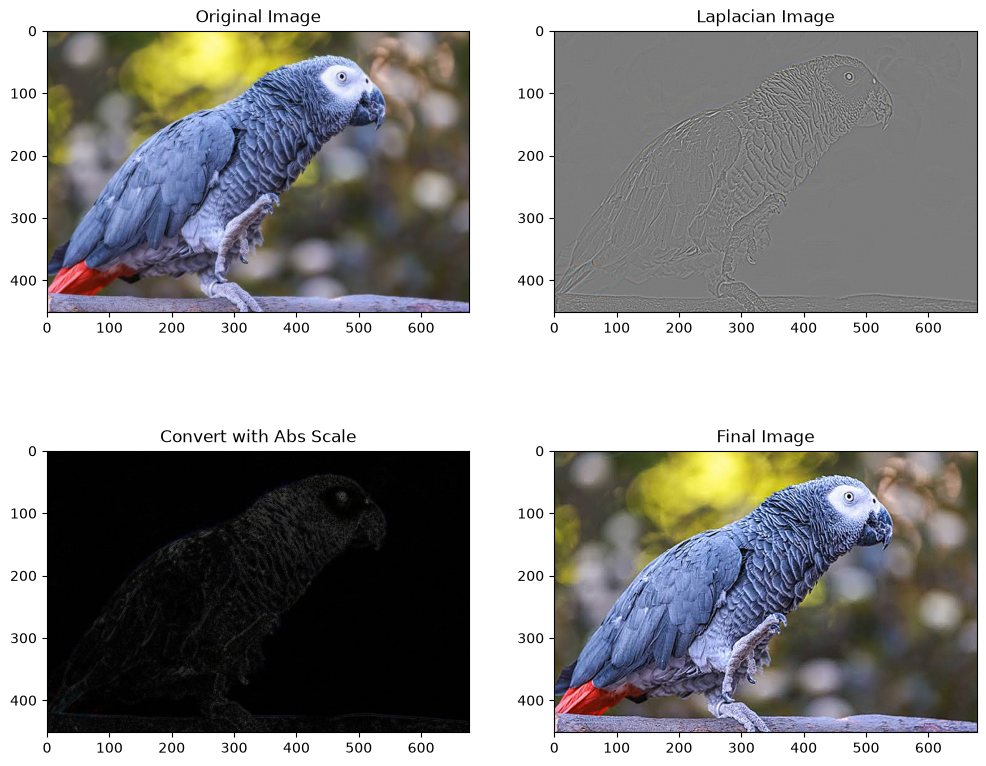

In [29]:
blurred = cv2.GaussianBlur(img, (3, 3), 0)

laplacian = cv2.Laplacian(blurred, cv2.CV_64F)
laplacian_view2 = cv2.normalize(laplacian, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
laplacian_8bit = cv2.convertScaleAbs(laplacian)

finalImage2 = np.clip(img.astype(np.float64) - laplacian, 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian_view2), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_8bit), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage2), plt.title('Final Image')
plt.show()

# **Mathematical and Statistical Filters**

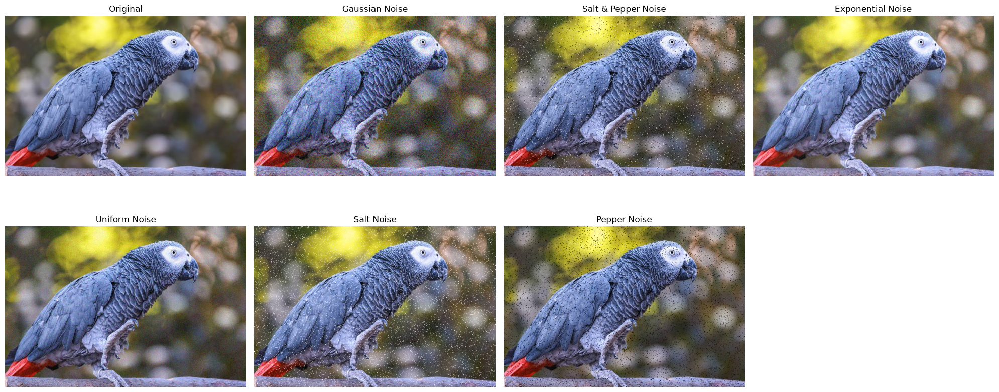

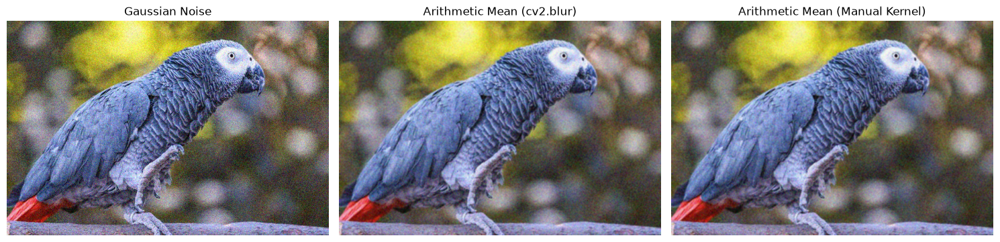

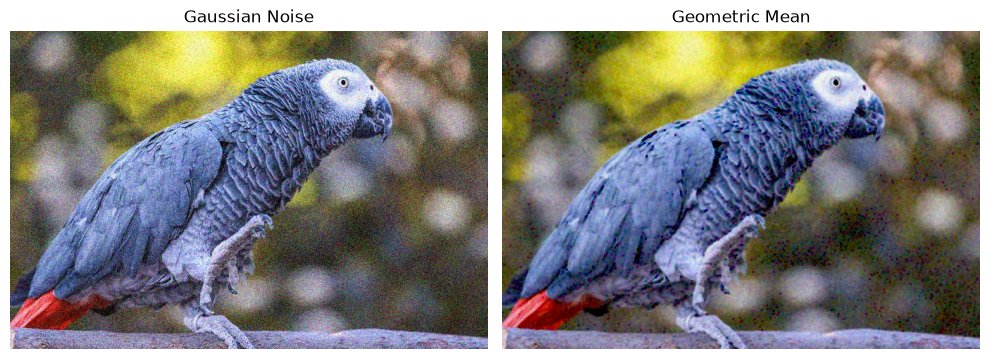

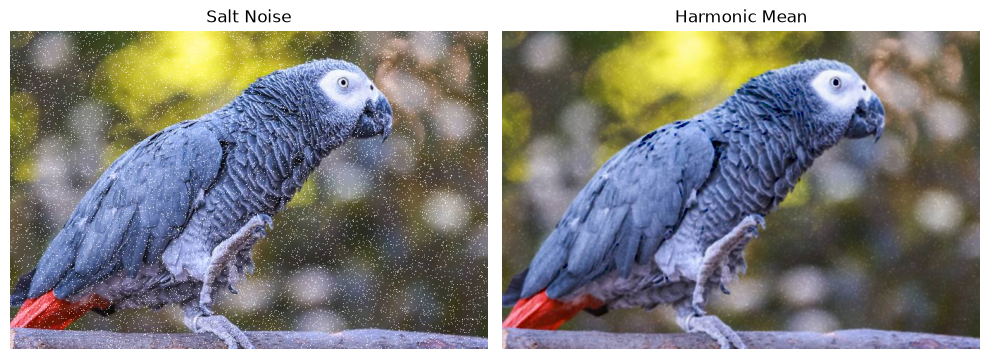

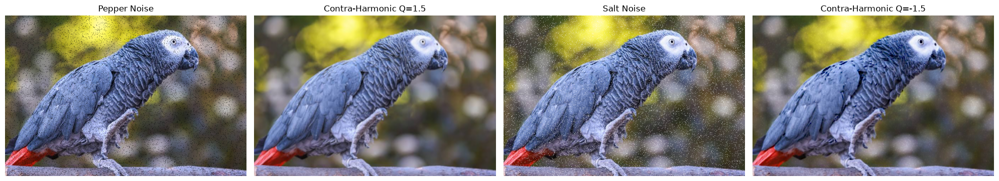

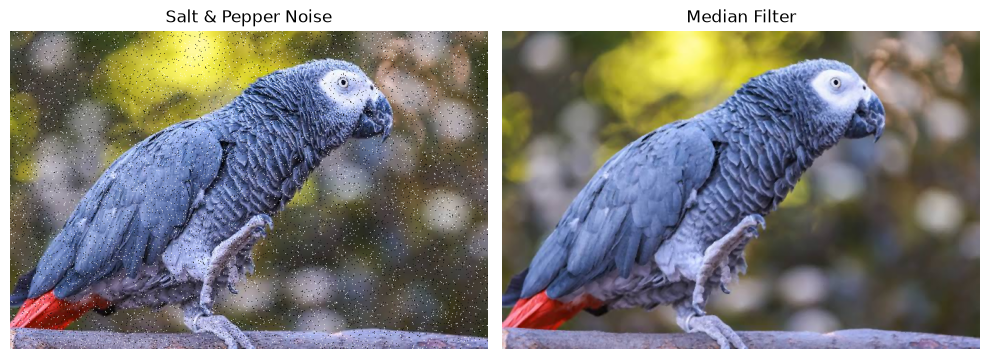

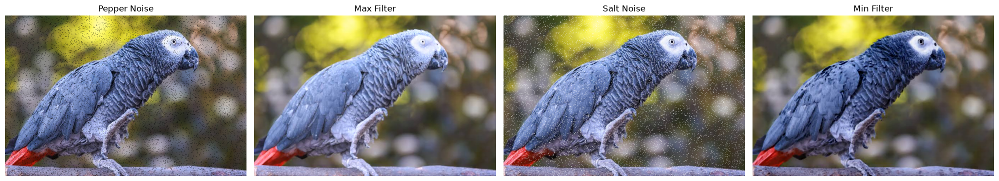

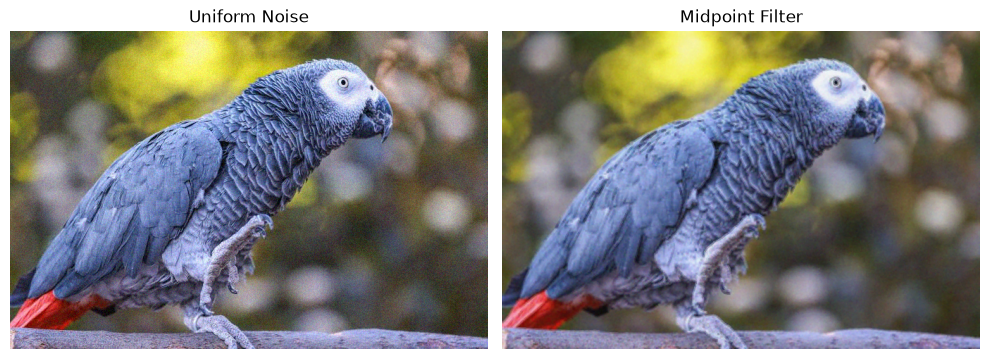

In [30]:
img = cv2.cvtColor(cv2.imread('../images/parrot.jpg'), cv2.COLOR_BGR2RGB)


def add_noise(image, noise_type, amount=0.04, s_vs_p=0.5):
    if noise_type == "gaussian":
        gauss = np.random.normal(0, 0.1, image.shape)
        return np.clip((image / 255 + gauss) * 255, 0, 255).astype(np.uint8)

    if noise_type == "salt_pepper":
        noisy = image.copy()
        rows, cols = image.shape[:2]
        num_salt = int(np.ceil(amount * rows * cols * s_vs_p))
        noisy[np.random.randint(0, rows, num_salt), np.random.randint(0, cols, num_salt)] = 255
        num_pepper = int(np.ceil(amount * rows * cols * (1 - s_vs_p)))
        noisy[np.random.randint(0, rows, num_pepper), np.random.randint(0, cols, num_pepper)] = 0
        return noisy

    if noise_type == "exponential":
        return np.clip(image + np.random.exponential(10.0, image.shape), 0, 255).astype(np.uint8)

    if noise_type == "uniform":
        return np.clip(image + np.random.uniform(-20, 20, image.shape), 0, 255).astype(np.uint8)


def arithmetic_mean_filter(image, kernel_size=3):
    kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
    return cv2.filter2D(image, -1, kernel)


def geometric_mean_filter(image, kernel_size=3):
    log_img = np.log(image.astype(np.float64) + 1e-6)
    kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
    return np.clip(np.exp(cv2.filter2D(log_img, -1, kernel)), 0, 255).astype(np.uint8)


def harmonic_mean_filter(image, kernel_size=3):
    reciprocal_img = 1.0 / (image.astype(np.float64) + 1e-6)
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    harmonic_mean = (kernel_size * kernel_size) / cv2.filter2D(reciprocal_img, -1, kernel)
    return np.clip(harmonic_mean, 0, 255).astype(np.uint8)


def contra_harmonic_mean(image, kernel_size=3, Q=0):
    img_float = image.astype(np.float64) + 1e-6
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    num_sum = cv2.filter2D(np.power(img_float, Q + 1), -1, kernel)
    den_sum = cv2.filter2D(np.power(img_float, Q), -1, kernel)
    return np.clip(num_sum / (den_sum + 1e-6), 0, 255).astype(np.uint8)


def midpoint_filter(image, kernel_size=3):
    kernel = np.ones((kernel_size, kernel_size), np.uint8)
    max_img = cv2.dilate(image, kernel).astype(np.float64)
    min_img = cv2.erode(image, kernel).astype(np.float64)
    return ((max_img + min_img) / 2).astype(np.uint8)


def show(images, titles, cols=None):
    cols = cols or min(len(images), 4)
    rows = int(np.ceil(len(images) / cols))
    plt.figure(figsize=(5 * cols, 4.5 * rows))
    for i, (image, title) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i + 1), plt.imshow(image), plt.title(title), plt.axis('off')
    plt.tight_layout()
    plt.show()


noise_gauss = add_noise(img, "gaussian")
noise_sp = add_noise(img, "salt_pepper")
noise_expo = add_noise(img, "exponential")
noise_uni = add_noise(img, "uniform")
noise_salt = add_noise(img, "salt_pepper", s_vs_p=1.0)
noise_pepper = add_noise(img, "salt_pepper", s_vs_p=0.0)

show([img, noise_gauss, noise_sp, noise_expo, noise_uni, noise_salt, noise_pepper],
     ['Original', 'Gaussian Noise', 'Salt & Pepper Noise', 'Exponential Noise',
      'Uniform Noise', 'Salt Noise', 'Pepper Noise'])

show([noise_gauss, cv2.blur(noise_gauss, (3, 3)), arithmetic_mean_filter(noise_gauss)],
     ['Gaussian Noise', 'Arithmetic Mean (cv2.blur)', 'Arithmetic Mean (Manual Kernel)'])

show([noise_gauss, geometric_mean_filter(noise_gauss)],
     ['Gaussian Noise', 'Geometric Mean'])

show([noise_salt, harmonic_mean_filter(noise_salt)],
     ['Salt Noise', 'Harmonic Mean'])

show([noise_pepper, contra_harmonic_mean(noise_pepper, Q=1.5),
      noise_salt, contra_harmonic_mean(noise_salt, Q=-1.5)],
     ['Pepper Noise', 'Contra-Harmonic Q=1.5', 'Salt Noise', 'Contra-Harmonic Q=-1.5'])

show([noise_sp, cv2.medianBlur(noise_sp, 3)],
     ['Salt & Pepper Noise', 'Median Filter'])

kernel = np.ones((3, 3), np.uint8)
show([noise_pepper, cv2.dilate(noise_pepper, kernel), noise_salt, cv2.erode(noise_salt, kernel)],
     ['Pepper Noise', 'Max Filter', 'Salt Noise', 'Min Filter'])

show([noise_uni, midpoint_filter(noise_uni)],
     ['Uniform Noise', 'Midpoint Filter'])